In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving prices.csv to prices.csv


In [ ]:
df = pd.read_csv("prices.csv")

print("Dimensions :", df.shape)

display(df.head())

print("\nInformations générales :")
df.info()

Dimensions : (851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05 00:00:00,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06 00:00:00,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07 00:00:00,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08 00:00:00,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11 00:00:00,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0



Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB


In [ ]:
# Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# Vérifier les doublons
print("\nNombre de doublons :", df.duplicated().sum())

# Statistiques descriptives
print("\nStatistiques descriptives :")
display(df.describe())

# Nombre d'entreprises différentes
print("\nNombre d'entreprises :", df["symbol"].nunique())

# Conversion des dates avec différents formats
df["date"] = pd.to_datetime(df["date"], format="mixed")

print("Date minimale :", df["date"].min())
print("Date maximale :", df["date"].max())

print("\nType de la colonne date :")
print(df["date"].dtype)

# Période couverte par les données
print("\nDate minimale :", df["date"].min())
print("Date maximale :", df["date"].max())

Valeurs manquantes :
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Nombre de doublons : 0

Statistiques descriptives :


,open,close,low,high,volume
count,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,70.836986,70.857109,70.118414,71.543476,5.415113e+06
std,83.695876,83.689686,82.877294,84.465504,1.249468e+07
min,0.850000,0.860000,0.830000,0.880000,0.000000e+00
25%,33.840000,33.849998,33.480000,34.189999,1.221500e+06
50%,52.770000,52.799999,52.230000,53.310001,2.476250e+06
75%,79.879997,79.889999,79.110001,80.610001,5.222500e+06
max,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08



Nombre d'entreprises : 501
Date minimale : 2010-01-04 00:00:00
Date maximale : 2016-12-30 00:00:00

Type de la colonne date :
datetime64[ns]

Date minimale : 2010-01-04 00:00:00
Date maximale : 2016-12-30 00:00:00


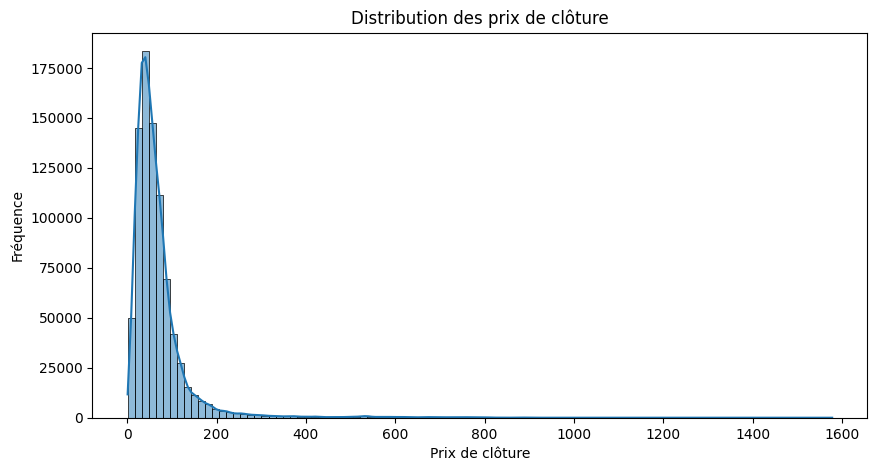

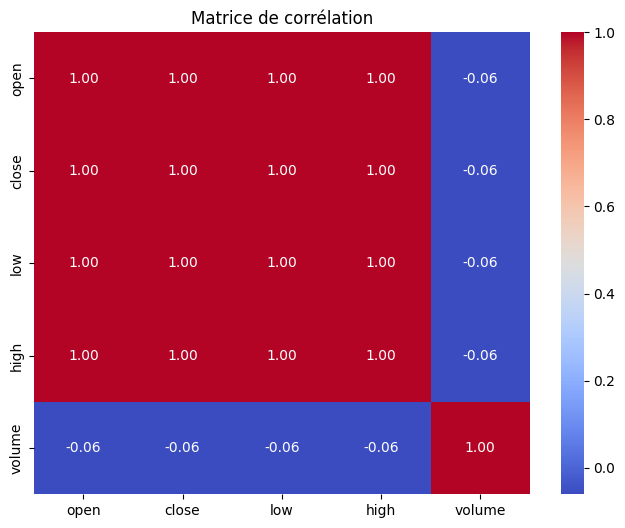

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graphique 1 : distribution des prix
plt.figure(figsize=(10, 5))

sns.histplot(df["close"], bins=100, kde=True)

plt.title("Distribution des prix de clôture")
plt.xlabel("Prix de clôture")
plt.ylabel("Fréquence")

plt.show()

# Graphique 2 : matrice de corrélation
numeric_cols = ["open", "close", "low", "high", "volume"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation")
plt.show()

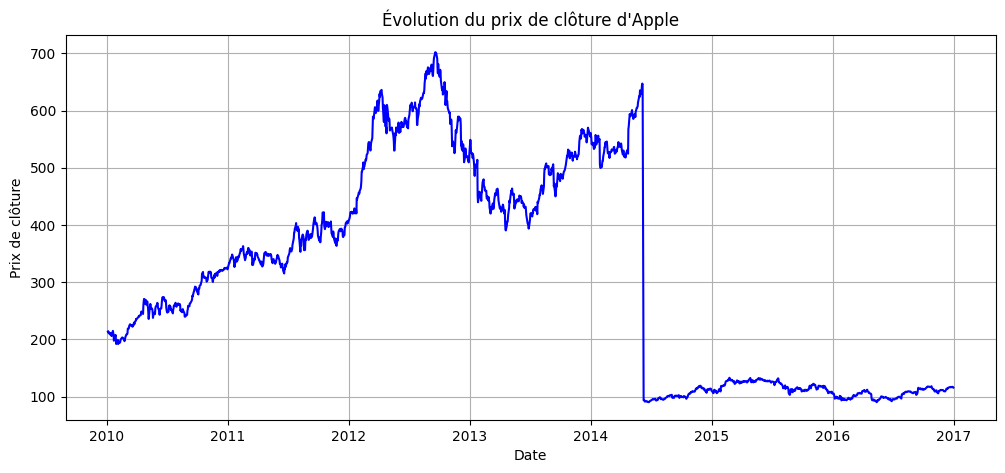

In [ ]:
# Sélectionner les données d'Apple
apple = df[df["symbol"] == "AAPL"].copy()

# Trier chronologiquement
apple = apple.sort_values("date")

# Visualiser l'évolution du prix
plt.figure(figsize=(12, 5))

plt.plot(
    apple["date"],
    apple["close"],
    color="blue"
)

plt.title("Évolution du prix de clôture d'Apple")
plt.xlabel("Date")
plt.ylabel("Prix de clôture")
plt.grid(True)
plt.show()

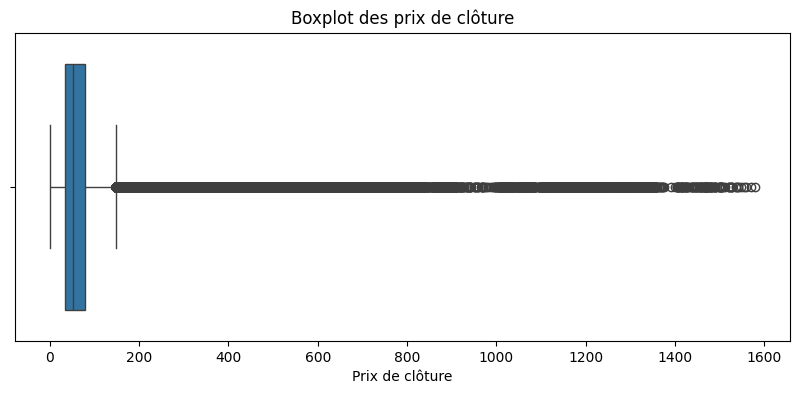

Nombre de valeurs extrêmes : 54651
Pourcentage : 6.42 %


In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["close"])

plt.title("Boxplot des prix de clôture")
plt.xlabel("Prix de clôture")
plt.show()

# Nombre de valeurs extrêmes selon la méthode IQR
Q1 = df["close"].quantile(0.25)
Q3 = df["close"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["close"] < lower_bound) |
    (df["close"] > upper_bound)
]

print("Nombre de valeurs extrêmes :", len(outliers))
print("Pourcentage :", round(len(outliers) / len(df) * 100, 2), "%")

In [ ]:
# Sélectionner Apple
apple = df[df["symbol"] == "AAPL"].copy()

# Trier les données chronologiquement
apple = apple.sort_values("date").reset_index(drop=True)

# Créer le prix de clôture du prochain jour de cotation
apple["target"] = apple["close"].shift(-1)

# Supprimer la dernière ligne sans cible
apple = apple.dropna(subset=["target"])

# Variables explicatives
features = ["open", "high", "low", "close", "volume"]

X = apple[features]
y = apple["target"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

display(apple[["date", "close", "target"]].head(10))

Dimensions de X : (1761, 5)
Dimensions de y : (1761,)


,date,close,target
0,2010-01-04,214.009998,214.379993
1,2010-01-05,214.379993,210.969995
2,2010-01-06,210.969995,210.580000
3,2010-01-07,210.580000,211.980005
4,2010-01-08,211.980005,210.110003
5,2010-01-11,210.110003,207.720001
6,2010-01-12,207.720001,210.650002
7,2010-01-13,210.650002,209.430000
8,2010-01-14,209.430000,205.930000
9,2010-01-15,205.930000,215.039995


In [ ]:
# ==========================================
# PRÉPARATION DES DONNÉES POUR LA RÉGRESSION
# ==========================================

# Sélectionner uniquement Apple
apple = df[df["symbol"] == "AAPL"].copy()

# Convertir la date au bon format
apple["date"] = pd.to_datetime(apple["date"])

# Trier chronologiquement
apple = apple.sort_values("date").reset_index(drop=True)

# Créer la variable cible :
# prix de clôture du jour suivant
apple["target"] = apple["close"].shift(-1)

# La dernière ligne n'a pas de target
apple = apple.dropna()

display(apple[["date", "open", "high", "low", "close", "volume", "target"]].head(10))

print("Nombre d'observations :", len(apple))

,date,open,high,low,close,volume,target
0,2010-01-04,213.429998,214.499996,212.380001,214.009998,123432400.0,214.379993
1,2010-01-05,214.599998,215.589994,213.249994,214.379993,150476200.0,210.969995
2,2010-01-06,214.379993,215.230000,210.750004,210.969995,138040000.0,210.580000
3,2010-01-07,211.750000,212.000006,209.050005,210.580000,119282800.0,211.980005
4,2010-01-08,210.299994,212.000006,209.060005,211.980005,111902700.0,210.110003
5,2010-01-11,212.799997,213.000002,208.450005,210.110003,115557400.0,207.720001
6,2010-01-12,209.189995,209.769995,206.419998,207.720001,148614900.0,210.650002
7,2010-01-13,207.870005,210.929995,204.099998,210.650002,151473000.0,209.430000
8,2010-01-14,210.110003,210.459997,209.020004,209.430000,108223500.0,205.930000
9,2010-01-15,210.929995,211.599997,205.869999,205.930000,148516900.0,215.039995


Nombre d'observations : 1761


In [ ]:
features = ["open", "high", "low", "close", "volume"]

X = apple[features].values
y = apple["target"].values.reshape(-1, 1)

print("Dimensions X :", X.shape)
print("Dimensions y :", y.shape)

Dimensions X : (1761, 5)
Dimensions y : (1761, 1)


In [ ]:
# 80 % entraînement / 20 % test
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)

Train : (1408, 5) (1408, 1)
Test  : (353, 5) (353, 1)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_X = StandardScaler()
scaler_y = StandardScaler()

# IMPORTANT :
# fit uniquement sur TRAIN
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_scaled,
    dtype=torch.float32
)

print(X_train_tensor.shape)
print(y_train_tensor.shape)
print(X_test_tensor.shape)
print(y_test_tensor.shape)

torch.Size([1408, 5])
torch.Size([1408, 1])
torch.Size([353, 5])
torch.Size([353, 1])


In [ ]:
batch_size = 32

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
import torch.nn as nn

class RegressionModel(nn.Module):

    def __init__(self):
        super(RegressionModel, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(5, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
model = RegressionModel()

print(model)

RegressionModel(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [ ]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# Optimiseur
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

train_losses = []
test_losses = []

train_r2_scores = []
test_r2_scores = []

from sklearn.metrics import r2_score

for epoch in range(epochs):

    # ===== ENTRAÎNEMENT =====
    model.train()

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        optimizer.step()

    # ===== ÉVALUATION =====
    model.eval()

    with torch.no_grad():

        train_pred = model(X_train_tensor)
        test_pred = model(X_test_tensor)

        train_loss = criterion(
            train_pred, y_train_tensor
        ).item()

        test_loss = criterion(
            test_pred, y_test_tensor
        ).item()

        train_r2 = r2_score(
            y_train_tensor.numpy(),
            train_pred.numpy()
        )

        test_r2 = r2_score(
            y_test_tensor.numpy(),
            test_pred.numpy()
        )

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_r2_scores.append(train_r2)
    test_r2_scores.append(test_r2)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train R2: {train_r2:.4f} | "
            f"Test R2: {test_r2:.4f}"
        )

Epoch 10/100 | Train Loss: 0.0093 | Test Loss: 0.0004 | Train R2: 0.9907 | Test R2: 0.8287
Epoch 20/100 | Train Loss: 0.0120 | Test Loss: 0.0001 | Train R2: 0.9880 | Test R2: 0.9459
Epoch 30/100 | Train Loss: 0.0093 | Test Loss: 0.0004 | Train R2: 0.9907 | Test R2: 0.7986
Epoch 40/100 | Train Loss: 0.0092 | Test Loss: 0.0001 | Train R2: 0.9908 | Test R2: 0.9390
Epoch 50/100 | Train Loss: 0.0115 | Test Loss: 0.0006 | Train R2: 0.9885 | Test R2: 0.7284
Epoch 60/100 | Train Loss: 0.0095 | Test Loss: 0.0008 | Train R2: 0.9905 | Test R2: 0.6131
Epoch 70/100 | Train Loss: 0.0093 | Test Loss: 0.0001 | Train R2: 0.9907 | Test R2: 0.9509
Epoch 80/100 | Train Loss: 0.0093 | Test Loss: 0.0002 | Train R2: 0.9907 | Test R2: 0.8845
Epoch 90/100 | Train Loss: 0.0094 | Test Loss: 0.0005 | Train R2: 0.9906 | Test R2: 0.7450
Epoch 100/100 | Train Loss: 0.0090 | Test Loss: 0.0003 | Train R2: 0.9910 | Test R2: 0.8557


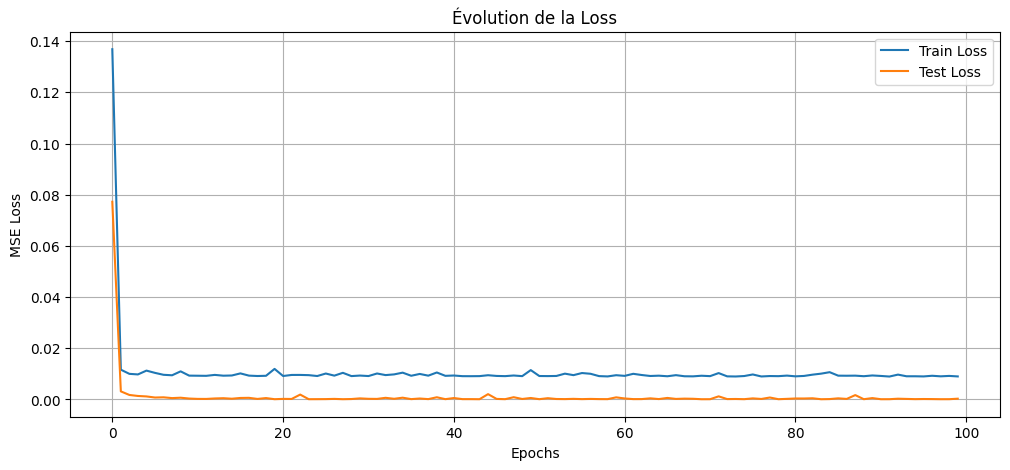

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(test_losses, label="Test Loss")

plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

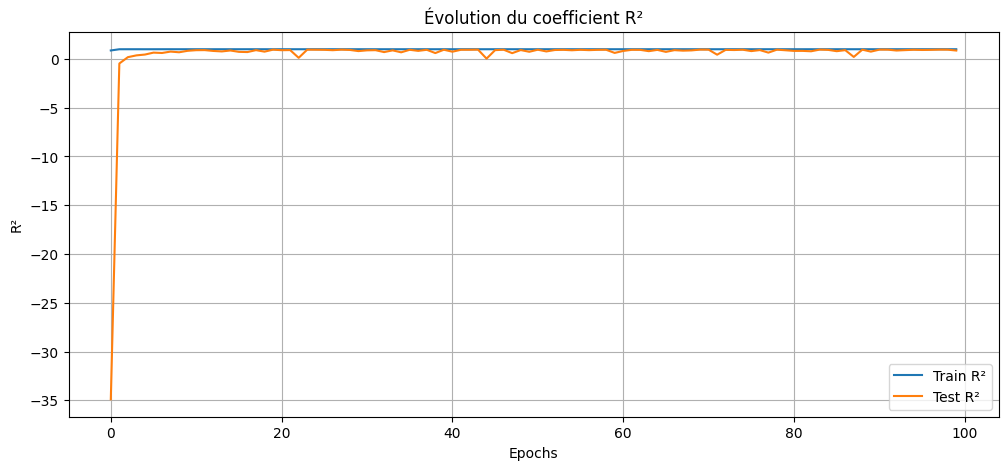

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(train_r2_scores, label="Train R²")
plt.plot(test_r2_scores, label="Test R²")

plt.title("Évolution du coefficient R²")
plt.xlabel("Epochs")
plt.ylabel("R²")

plt.legend()
plt.grid(True)
plt.show()

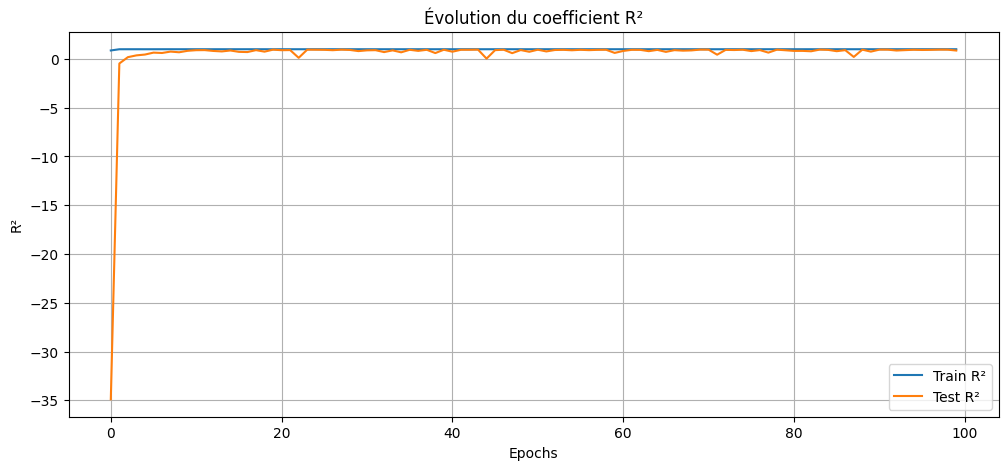

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(train_r2_scores, label="Train R²")
plt.plot(test_r2_scores, label="Test R²")

plt.title("Évolution du coefficient R²")
plt.xlabel("Epochs")
plt.ylabel("R²")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

model.eval()

with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy()

# Revenir à l'échelle réelle
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test_scaled)

# Métriques du MLP
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print("=== Performances MLP ===")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f} $")
print(f"MAE  : {mae:.4f} $")
print(f"R²   : {r2:.4f}")

# Baseline naïve : demain = aujourd'hui
y_naive = X_test[:, 3].reshape(-1, 1)

print("\n=== Baseline naïve ===")
print(f"RMSE : {np.sqrt(mean_squared_error(y_true, y_naive)):.4f} $")
print(f"MAE  : {mean_absolute_error(y_true, y_naive):.4f} $")
print(f"R²   : {r2_score(y_true, y_naive):.4f}")

=== Performances MLP ===
MSE  : 9.1885
RMSE : 3.0313 $
MAE  : 2.6728 $
R²   : 0.8557

=== Baseline naïve ===
RMSE : 1.7226 $
MAE  : 1.2216 $
R²   : 0.9534


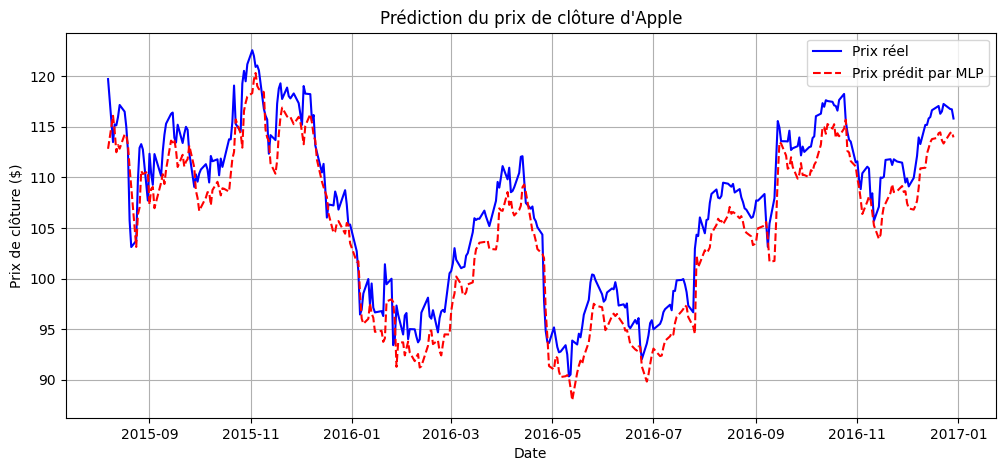

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    apple["date"].iloc[split_index:],
    y_true.flatten(),
    label="Prix réel",
    color="blue"
)

plt.plot(
    apple["date"].iloc[split_index:],
    y_pred.flatten(),
    label="Prix prédit par MLP",
    color="red",
    linestyle="--"
)

plt.title("Prédiction du prix de clôture d'Apple")
plt.xlabel("Date")
plt.ylabel("Prix de clôture ($)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Examiner les prix autour du split Apple de 2014

split_period = apple[
    (apple["date"] >= "2014-06-02") &
    (apple["date"] <= "2014-06-13")
]

display(
    split_period[
        ["date", "open", "high", "low", "close", "volume"]
    ]
)

,date,open,high,low,close,volume
1109,2014-06-02,633.959984,634.830017,622.500015,628.650009,92337700.0
1110,2014-06-03,628.459991,638.740013,628.250000,637.539986,73177300.0
1111,2014-06-04,637.440010,647.890022,636.109993,644.819992,83870500.0
1112,2014-06-05,646.199997,649.370003,642.610008,647.349983,75951400.0
1113,2014-06-06,649.900002,651.259979,644.470024,645.570023,87484600.0
1114,2014-06-09,92.699997,93.879997,91.750000,93.699997,75415000.0
1115,2014-06-10,94.730003,95.050003,93.570000,94.250000,62777000.0
1116,2014-06-11,94.129997,94.760002,93.470001,93.860001,45681000.0
1117,2014-06-12,94.040001,94.120003,91.900002,92.290001,54749000.0
1118,2014-06-13,92.199997,92.440002,90.879997,91.279999,54525000.0


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Repartir des données originales
apple = df[df["symbol"] == "AAPL"].copy()
apple["date"] = pd.to_datetime(apple["date"])
apple = apple.sort_values("date").reset_index(drop=True)

# Variable cible : clôture du lendemain
apple["target"] = apple["close"].shift(-1)
apple = apple.dropna(subset=["target"])

features = ["open", "high", "low", "close", "volume"]

X = apple[features].values
y = apple["target"].values.reshape(-1, 1)

# Séparation chronologique
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
X_val = X[train_end:val_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

# Standardisation uniquement sur le train
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled = scaler_y.transform(y_val)
y_test_scaled = scaler_y.transform(y_test)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

Train : (1232, 5)
Validation : (264, 5)
Test : (265, 5)


In [ ]:
import torch
import torch.nn as nn

class MLPRegressorTorch(nn.Module):

    def __init__(self, input_size=5, hidden_layers=(64, 32)):
        super().__init__()

        layers = []
        previous_size = input_size

        for neurons in hidden_layers:
            layers.append(nn.Linear(previous_size, neurons))
            layers.append(nn.ReLU())
            previous_size = neurons

        layers.append(nn.Linear(previous_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [ ]:
model1 = MLPRegressorTorch(hidden_layers=(64, 32))
model2 = MLPRegressorTorch(hidden_layers=(128, 64))
model3 = MLPRegressorTorch(hidden_layers=(64, 32, 16))

print(model1)

MLPRegressorTorch(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
import torch
import torch.nn as nn
import numpy as np

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

class TorchRegressor(RegressorMixin, BaseEstimator):

    def __init__(
        self,
        hidden_layers=(64, 32),
        learning_rate=0.001,
        optimizer_name="Adam",
        epochs=50,
        batch_size=32
    ):
        self.hidden_layers = hidden_layers
        self.learning_rate = learning_rate
        self.optimizer_name = optimizer_name
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):

        # Normalisation propre à chaque entraînement
        self.scaler_X_ = StandardScaler()
        self.scaler_y_ = StandardScaler()

        X_scaled = self.scaler_X_.fit_transform(
            np.asarray(X)
        )

        y_scaled = self.scaler_y_.fit_transform(
            np.asarray(y).reshape(-1, 1)
        )

        X_tensor = torch.tensor(
            X_scaled, dtype=torch.float32
        )

        y_tensor = torch.tensor(
            y_scaled, dtype=torch.float32
        )

        dataset = TensorDataset(X_tensor, y_tensor)

        loader = DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=True
        )

        self.model_ = MLPRegressorTorch(
            input_size=X_tensor.shape[1],
            hidden_layers=self.hidden_layers
        )

        criterion = nn.MSELoss()

        if self.optimizer_name == "Adam":
            optimizer = torch.optim.Adam(
                self.model_.parameters(),
                lr=self.learning_rate
            )

        elif self.optimizer_name == "SGD":
            optimizer = torch.optim.SGD(
                self.model_.parameters(),
                lr=self.learning_rate
            )

        else:
            raise ValueError("Optimiseur non reconnu")

        for epoch in range(self.epochs):

            self.model_.train()

            for X_batch, y_batch in loader:

                optimizer.zero_grad()

                predictions = self.model_(X_batch)

                loss = criterion(predictions, y_batch)

                loss.backward()

                optimizer.step()

        return self

    def predict(self, X):

        X_scaled = self.scaler_X_.transform(
            np.asarray(X)
        )

        X_tensor = torch.tensor(
            X_scaled, dtype=torch.float32
        )

        self.model_.eval()

        with torch.no_grad():
            predictions = self.model_(X_tensor).numpy()

        predictions = self.scaler_y_.inverse_transform(
            predictions
        )

        return predictions.ravel()

In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "hidden_layers": [
        (64, 32),
        (128, 64),
        (64, 32, 16)
    ],
    "learning_rate": [0.01, 0.001],
    "optimizer_name": ["Adam", "SGD"],
    "epochs": [50, 100]
}

tscv = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=TorchRegressor(),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_squared_error",
    n_jobs=1,
    verbose=2,
    refit=True
)

In [ ]:
# Utiliser les données brutes d'entraînement.
# Les scalers sont intégrés dans TorchRegressor.

grid_search.fit(
    X_train,
    y_train.ravel()
)

print("\nMeilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur MSE moyen en validation croisée :")
print(-grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   0.7s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   1.4s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   2.1s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   0.5s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   1.0s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   1.4s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   1.0s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   1.8s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   2.3s
[CV

In [ ]:
# Utiliser les données brutes d'entraînement.
# Les scalers sont intégrés dans TorchRegressor.

grid_search.fit(
    X_train,
    y_train.ravel()
)

print("\nMeilleurs hyperparamètres :")
print(grid_search.best_params_)

print("\nMeilleur MSE moyen en validation croisée :")
print(-grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   0.7s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   1.3s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   2.0s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   0.5s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   0.9s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   1.3s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   0.7s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   1.7s
[CV] END epochs=50, hidden_layers=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   2.7s
[CV

In [ ]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

best_results = results[
    [
        "param_hidden_layers",
        "param_learning_rate",
        "param_optimizer_name",
        "param_epochs",
        "mean_test_score",
        "rank_test_score"
    ]
].copy()

best_results["MSE"] = -best_results["mean_test_score"]

best_results = best_results.sort_values("rank_test_score")

display(best_results.head(10))

,param_hidden_layers,param_learning_rate,param_optimizer_name,param_epochs,mean_test_score,rank_test_score,MSE
2,"(64, 32)",0.001,Adam,50,-451.034912,1,451.034912
10,"(64, 32, 16)",0.001,Adam,50,-456.295808,2,456.295808
4,"(128, 64)",0.010,Adam,50,-456.888155,3,456.888155
16,"(128, 64)",0.010,Adam,100,-466.115300,4,466.115300
8,"(64, 32, 16)",0.010,Adam,50,-467.831742,5,467.831742
6,"(128, 64)",0.001,Adam,50,-478.280941,6,478.280941
22,"(64, 32, 16)",0.001,Adam,100,-486.253151,7,486.253151
14,"(64, 32)",0.001,Adam,100,-489.098025,8,489.098025
0,"(64, 32)",0.010,Adam,50,-502.395116,9,502.395116
17,"(128, 64)",0.010,SGD,100,-507.587798,10,507.587798


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Récupérer le meilleur modèle
best_model = grid_search.best_estimator_

# Prédictions sur validation
y_val_pred = best_model.predict(X_val)

# Calcul des métriques
val_mse = mean_squared_error(y_val.ravel(), y_val_pred)
val_rmse = np.sqrt(val_mse)
val_mae = mean_absolute_error(y_val.ravel(), y_val_pred)
val_r2 = r2_score(y_val.ravel(), y_val_pred)

# Baseline naïve : demain = aujourd'hui
y_val_naive = X_val[:, 3]

print("=== MLP optimisé : validation ===")
print(f"MSE  : {val_mse:.4f}")
print(f"RMSE : {val_rmse:.4f} $")
print(f"MAE  : {val_mae:.4f} $")
print(f"R²   : {val_r2:.4f}")

print("\n=== Baseline naïve : validation ===")
print(f"RMSE : {np.sqrt(mean_squared_error(y_val.ravel(), y_val_naive)):.4f} $")
print(f"MAE  : {mean_absolute_error(y_val.ravel(), y_val_naive):.4f} $")
print(f"R²   : {r2_score(y_val.ravel(), y_val_naive):.4f}")

=== MLP optimisé : validation ===
MSE  : 33.2360
RMSE : 5.7651 $
MAE  : 5.3960 $
R²   : 0.3906

=== Baseline naïve : validation ===
RMSE : 1.9566 $
MAE  : 1.4899 $
R²   : 0.9298


In [ ]:
import torch
import torch.nn as nn

class RegularizedMLP(nn.Module):

    def __init__(
        self,
        input_size=5,
        hidden_layers=(64, 32),
        dropout_rate=0.2
    ):
        super().__init__()

        layers = []
        previous_size = input_size

        for neurons in hidden_layers:

            layers.append(nn.Linear(previous_size, neurons))
            layers.append(nn.ReLU())

            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))

            previous_size = neurons

        layers.append(nn.Linear(previous_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [ ]:
regularized_model = RegularizedMLP(
    input_size=5,
    hidden_layers=(64, 32),
    dropout_rate=0.2
)

print(regularized_model)

RegularizedMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
import copy

def train_regularized_model(
    dropout_rate=0.0,
    weight_decay=0.0,
    early_stopping=False,
    epochs=100,
    patience=15
):

    # Reproductibilité
    torch.manual_seed(42)
    np.random.seed(42)
    random.seed(42)

    model = RegularizedMLP(
        input_size=5,
        hidden_layers=(64, 32),
        dropout_rate=dropout_rate
    )

    criterion = torch.nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=weight_decay
    )

    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_r2": [],
        "val_r2": []
    }

    best_val_loss = float("inf")
    best_weights = None
    patience_counter = 0

    for epoch in range(epochs):

        # Entraînement
        model.train()

        for X_batch, y_batch in loader:

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            loss.backward()
            optimizer.step()

        # Évaluation
        model.eval()

        with torch.no_grad():

            train_pred = model(X_train_tensor)
            val_pred = model(X_val_tensor)

            train_loss = criterion(
                train_pred, y_train_tensor
            ).item()

            val_loss = criterion(
                val_pred, y_val_tensor
            ).item()

            train_r2 = r2_score(
                y_train_tensor.numpy(),
                train_pred.numpy()
            )

            val_r2 = r2_score(
                y_val_tensor.numpy(),
                val_pred.numpy()
            )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_r2"].append(train_r2)
        history["val_r2"].append(val_r2)

        # Sauvegarder les meilleurs poids
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0

        else:
            patience_counter += 1

        # Early Stopping
        if early_stopping and patience_counter >= patience:

            print(f"Early Stopping à l'epoch {epoch + 1}")
            break

    # Restaurer les meilleurs poids uniquement
    # pour le modèle avec Early Stopping
    if early_stopping and best_weights is not None:
        model.load_state_dict(best_weights)

    return model, history

In [ ]:
experiments = {
    "MLP sans régularisation": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0,
        "early_stopping": False
    },

    "MLP + Dropout": {
        "dropout_rate": 0.2,
        "weight_decay": 0.0,
        "early_stopping": False
    },

    "MLP + L2": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0001,
        "early_stopping": False
    },

    "MLP + Dropout + L2 + Early Stopping": {
        "dropout_rate": 0.2,
        "weight_decay": 0.0001,
        "early_stopping": True
    }
}

trained_models = {}
histories = {}

for name, params in experiments.items():

    print(f"\nEntraînement : {name}")

    model_exp, history_exp = train_regularized_model(
        **params
    )

    trained_models[name] = model_exp
    histories[name] = history_exp

    print(
        f"Epochs : {len(history_exp['train_loss'])} | "
        f"Train Loss : {history_exp['train_loss'][-1]:.4f} | "
        f"Validation Loss : {history_exp['val_loss'][-1]:.4f}"
    )


Entraînement : MLP sans régularisation


NameError: name 'X_val_tensor' is not defined

In [ ]:
import pandas as pd

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

results_reg = []

for name, model_exp in trained_models.items():

    model_exp.eval()

    with torch.no_grad():
        pred_scaled = model_exp(X_val_tensor).numpy()

    pred = scaler_y.inverse_transform(pred_scaled)

    true = y_val.ravel()
    pred = pred.ravel()

    results_reg.append({
        "Modèle": name,
        "RMSE": np.sqrt(mean_squared_error(true, pred)),
        "MAE": mean_absolute_error(true, pred),
        "R²": r2_score(true, pred),
        "Epochs": len(histories[name]["train_loss"])
    })

results_reg_df = pd.DataFrame(results_reg)

display(
    results_reg_df.sort_values("RMSE")
)

KeyError: 'RMSE'

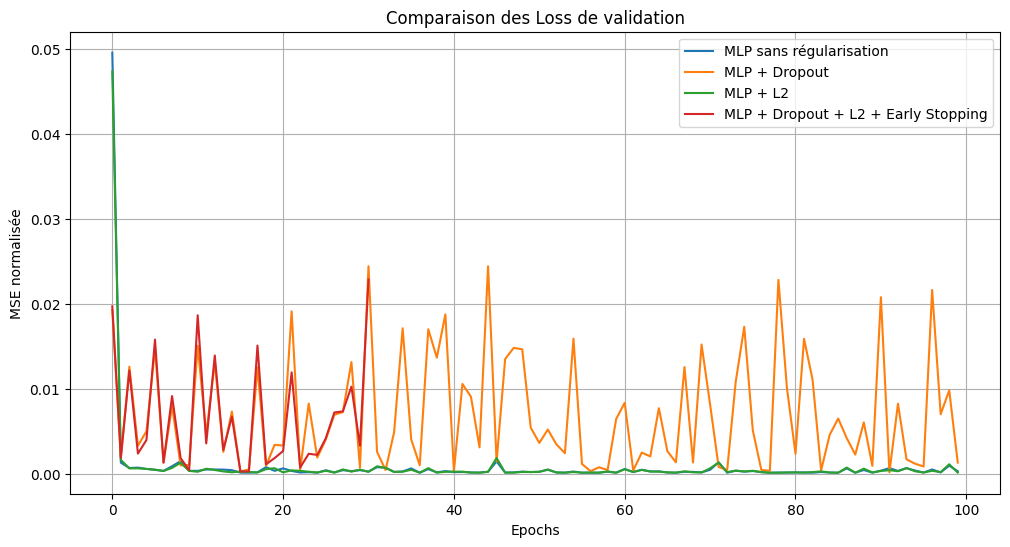

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.title("Comparaison des Loss de validation")
plt.xlabel("Epochs")
plt.ylabel("MSE normalisée")
plt.legend()
plt.grid(True)
plt.show()

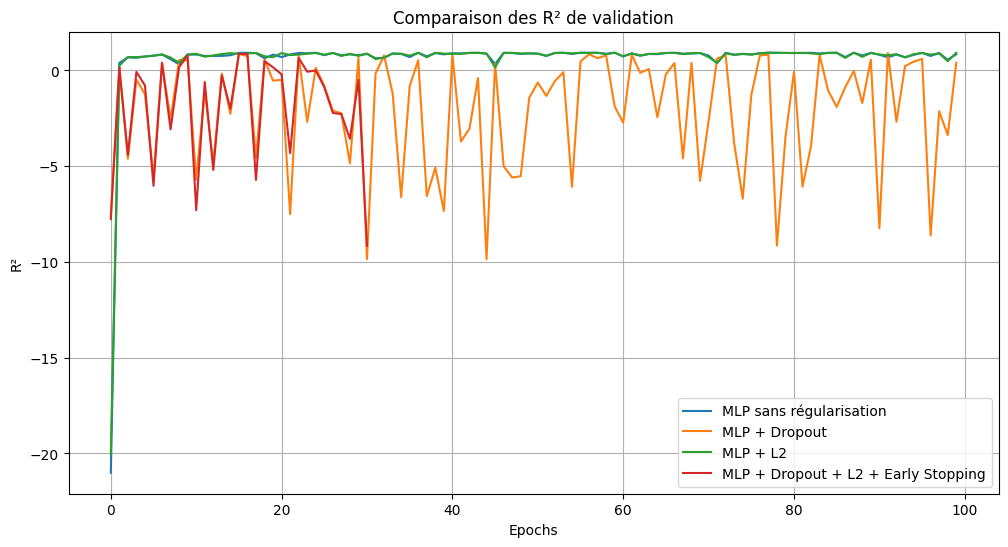

In [ ]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history["val_r2"],
        label=name
    )

plt.title("Comparaison des R² de validation")
plt.xlabel("Epochs")
plt.ylabel("R²")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Recharger le dataset si nécessaire
if "df" not in globals():
    df = pd.read_csv("prices.csv")

# Sélectionner Apple
apple = df[df["symbol"] == "AAPL"].copy()

# Trier chronologiquement
apple["date"] = pd.to_datetime(apple["date"])
apple = apple.sort_values("date").reset_index(drop=True)

# Prix de clôture du lendemain
apple["target"] = apple["close"].shift(-1)
apple = apple.dropna(subset=["target"])

# Variables explicatives
features = ["open", "high", "low", "close", "volume"]

X = apple[features].values
y = apple["target"].values.reshape(-1, 1)

# Découpage chronologique
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
X_val = X[train_end:val_end]
X_test = X[val_end:]

y_train = y[:train_end]
y_val = y[train_end:val_end]
y_test = y[val_end:]

print("X :", X.shape)
print("y :", y.shape)
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

X : (1761, 5)
y : (1761, 1)
Train : (1232, 5)
Validation : (264, 5)
Test : (265, 5)


In [ ]:
import torch
import torch.nn as nn
import numpy as np

from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

# Train + Validation
X_train_final = X[:val_end]
y_train_final = y[:val_end]

# Normalisation
scaler_X_final = StandardScaler()
scaler_y_final = StandardScaler()

X_train_final_scaled = scaler_X_final.fit_transform(X_train_final)
y_train_final_scaled = scaler_y_final.fit_transform(y_train_final)

X_test_final_scaled = scaler_X_final.transform(X_test)

# Conversion en tenseurs
X_train_final_tensor = torch.tensor(
    X_train_final_scaled, dtype=torch.float32
)

y_train_final_tensor = torch.tensor(
    y_train_final_scaled, dtype=torch.float32
)

X_test_final_tensor = torch.tensor(
    X_test_final_scaled, dtype=torch.float32
)

# Modèle final : MLP + L2
final_model = RegularizedMLP(
    input_size=5,
    hidden_layers=(64, 32),
    dropout_rate=0.0
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

loader = DataLoader(
    TensorDataset(X_train_final_tensor, y_train_final_tensor),
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

# Entraînement
for epoch in range(100):

    final_model.train()

    for X_batch, y_batch in loader:

        optimizer.zero_grad()

        predictions = final_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

print("Entraînement final terminé !")

Entraînement final terminé !


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

final_model.eval()

with torch.no_grad():
    predictions_scaled = final_model(
        X_test_final_tensor
    ).numpy()

# Revenir aux prix réels en dollars
y_test_pred = scaler_y_final.inverse_transform(
    predictions_scaled
).ravel()

y_test_true = y_test.ravel()

# Baseline : prix de demain = prix d'aujourd'hui
y_test_naive = X_test[:, 3]

print("=== MLP + L2 : TEST FINAL ===")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_true, y_test_pred)):.4f} $")
print(f"MAE  : {mean_absolute_error(y_test_true, y_test_pred):.4f} $")
print(f"R²   : {r2_score(y_test_true, y_test_pred):.4f}")

print("\n=== BASELINE NAÏVE : TEST ===")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_true, y_test_naive)):.4f} $")
print(f"MAE  : {mean_absolute_error(y_test_true, y_test_naive):.4f} $")
print(f"R²   : {r2_score(y_test_true, y_test_naive):.4f}")

=== MLP + L2 : TEST FINAL ===
RMSE : 1.6671 $
MAE  : 1.2390 $
R²   : 0.9505

=== BASELINE NAÏVE : TEST ===
RMSE : 1.5043 $
MAE  : 1.0635 $
R²   : 0.9597


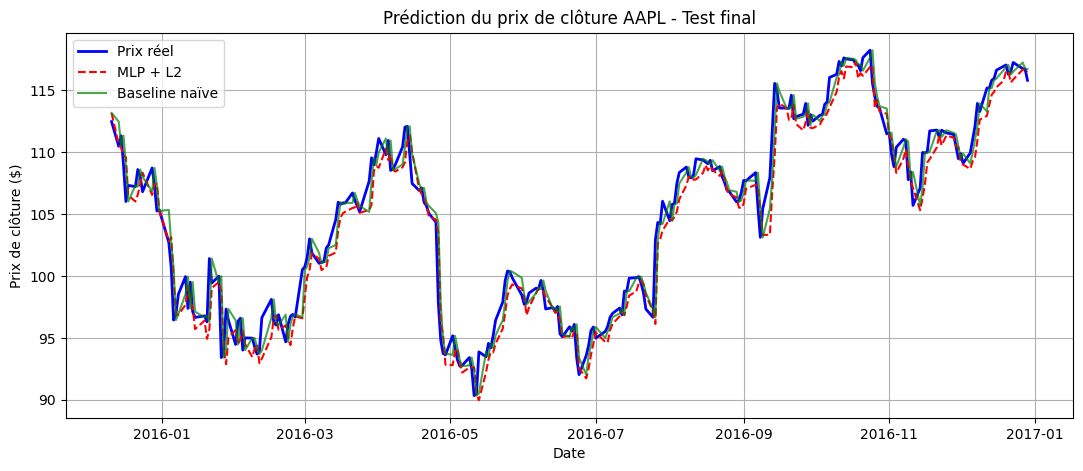

In [ ]:
import matplotlib.pyplot as plt

dates_test = apple["date"].iloc[val_end:]

plt.figure(figsize=(13, 5))

plt.plot(
    dates_test,
    y_test_true,
    label="Prix réel",
    color="blue",
    linewidth=2
)

plt.plot(
    dates_test,
    y_test_pred,
    label="MLP + L2",
    color="red",
    linestyle="--"
)

plt.plot(
    dates_test,
    y_test_naive,
    label="Baseline naïve",
    color="green",
    alpha=0.7
)

plt.title("Prédiction du prix de clôture AAPL - Test final")
plt.xlabel("Date")
plt.ylabel("Prix de clôture ($)")
plt.legend()
plt.grid(True)
plt.show()